In [1]:
from pathlib import Path
import sys
import json
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "a2_src").exists():
    PROJECT_ROOT = Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RUN_TRAINING = False
TRAIN_EPOCHS = 15
RUN_ABLATION = True
RUN_EVALUATION = True

from a2_src.config import (
    TRAIN_DIR, VAL_DIR, TEST_DIR, CLASSES, DEVICE,
    SOTA_MODEL_PATH, ABLATION_MODEL_PATH, A2_REPORTS_DIR, A2_FIGURES_DIR,
)
print(f"Project: {PROJECT_ROOT}")
print(f"Device: {DEVICE}")
print(f"Classes: {CLASSES}")

Project: C:\Users\danil\PycharmProjects\rps_assignment
Device: cpu
Classes: ['paper', 'rock', 'scissors']


In [2]:
def count_split(split_dir):
    return {c: len(list((split_dir / c).glob("*.jpg"))) + len(list((split_dir / c).glob("*.png"))) for c in CLASSES}

split_counts = {
    "train": count_split(TRAIN_DIR),
    "validation": count_split(VAL_DIR),
    "test": count_split(TEST_DIR),
}
counts_df = pd.DataFrame(split_counts).reindex(CLASSES)
display(counts_df)
assert all(counts_df.loc[c].sum() > 0 for c in CLASSES), "Every class must contain images in all splits."
print(f"Total images: {int(counts_df.to_numpy().sum())}")

,train,validation,test
paper,196,42,43
rock,178,38,39
scissors,207,44,46


Total images: 833


In [3]:
from a2_src.train_sota import run_training

def train_a2_models():
    print("Training SOTA model with ArtAug")
    sota_model, sota_history = run_training(use_artaug=True, epochs=TRAIN_EPOCHS)
    if RUN_ABLATION:
        print("Training ablation model without ArtAug")
        ablation_model, ablation_history = run_training(use_artaug=False, epochs=TRAIN_EPOCHS)
    else:
        ablation_model, ablation_history = None, None
    return sota_model, sota_history, ablation_model, ablation_history

should_train = (
    RUN_TRAINING
    or not SOTA_MODEL_PATH.exists()
    or (RUN_ABLATION and not ABLATION_MODEL_PATH.exists())
)
if should_train:
    train_a2_models()
else:
    print("Using existing checkpoints")

Using existing checkpoints


In [4]:
import importlib
import a2_src.evaluate_a2 as evaluate_a2

evaluate_a2 = importlib.reload(evaluate_a2)

if RUN_EVALUATION:
    if not SOTA_MODEL_PATH.exists():
        raise FileNotFoundError("SOTA checkpoint is missing. Set RUN_TRAINING = True and rerun the training cell.")
    if RUN_ABLATION and not ABLATION_MODEL_PATH.exists():
        raise FileNotFoundError("Ablation checkpoint is missing. Set RUN_TRAINING = True and rerun both models.")
    evaluate_a2.run_full_evaluation()
    print(f"Evaluation artifacts written to: {A2_REPORTS_DIR}")
else:
    print("Evaluation skipped")

Assignment 2 evaluation
Device: cpu
Saved Grad-CAM explainability panel to: C:\Users\danil\PycharmProjects\rps_assignment\a2_reports\figures\gradcam_gallery.png
Scenario [Clean Baseline]: Accuracy = 99.22% | F1 = 0.9919
Scenario [Low Light (0.35x)]: Accuracy = 95.31% | F1 = 0.9533
Scenario [Low Light + ArtAug Polish]: Accuracy = 94.53% | F1 = 0.9439
Scenario [Severe Motion Blur]: Accuracy = 99.22% | F1 = 0.9925
Scenario [Sensor Noise (ISO 6400)]: Accuracy = 98.44% | F1 = 0.9847
Scenario [Compound Stress (Dim+Blur+Noise)]: Accuracy = 90.62% | F1 = 0.9054

Benchmark Table generated successfully:
| Stage                 | Model                           | Clean Accuracy   |   Macro F1 |   Latency (ms) |   FPS |   Model Size (MB) |
|:----------------------|:--------------------------------|:-----------------|-----------:|---------------:|------:|------------------:|
| Assignment 1 Baseline | SVM Baseline (RBF)              | 93.75%           |     0.9369 |           2.77 | 360.5 |         

In [5]:
required_outputs = [
    A2_FIGURES_DIR / "confusion_matrix_sota.png",
    A2_FIGURES_DIR / "gradcam_gallery.png",
    A2_FIGURES_DIR / "stress_test_robustness.png",
    A2_REPORTS_DIR / "a2_evaluation_summary.json",
]
missing_outputs = [str(p) for p in required_outputs if not p.exists()]
if RUN_EVALUATION and missing_outputs:
    raise FileNotFoundError("Missing A2 outputs: " + ", ".join(missing_outputs))
print("A2 output validation:", "OK" if not missing_outputs else "not run")

A2 output validation: OK


In [6]:
import cv2
import torch
import torch.nn.functional as F
from a2_src.sota_model import build_sota_model
from a2_src.artaug import generate_stress_environment, polish_low_exposure_frame, get_eval_transforms
from a2_src.gradcam import GradCAM


def load_sota_for_demo():
    model = build_sota_model(num_classes=len(CLASSES), pretrained=False)
    checkpoint = torch.load(SOTA_MODEL_PATH, map_location=DEVICE, weights_only=False)
    state_dict = checkpoint.get("model_state_dict", checkpoint)
    model.load_state_dict(state_dict)
    model.to(DEVICE).eval()
    return model


def predict_image(image_path, exposure=0.35, blur_kernel=1, noise_level=0.0, use_artaug=True):
    image_path = Path(image_path)
    bgr = cv2.imread(str(image_path))
    if bgr is None:
        raise FileNotFoundError(f"Could not read image: {image_path}")

    original_bgr = cv2.resize(bgr, (224, 224))
    stressed_bgr = generate_stress_environment(original_bgr, exposure, blur_kernel, noise_level)
    processed_bgr = stressed_bgr
    if use_artaug and exposure < 0.75:
        processed_bgr = polish_low_exposure_frame(stressed_bgr)

    model = load_sota_for_demo()
    gradcam = GradCAM(model, model.get_gradcam_target_layer())
    rgb = cv2.cvtColor(processed_bgr, cv2.COLOR_BGR2RGB)
    tensor = get_eval_transforms()(Image.fromarray(rgb)).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        probabilities = F.softmax(model(tensor), dim=1)[0].cpu().numpy()
    pred_idx = int(np.argmax(probabilities))
    heatmap = gradcam.generate_heatmap(tensor, target_class=pred_idx)
    overlay = gradcam.overlay_heatmap(rgb, heatmap, alpha=0.55, colormap=cv2.COLORMAP_VIRIDIS)
    gradcam.remove_hooks()

    label = f"SYNTHETIC STRESS TEST | exposure={exposure:.2f} | blur={blur_kernel} | noise={noise_level:.1f}"
    stressed_rgb = cv2.cvtColor(stressed_bgr, cv2.COLOR_BGR2RGB)
    marked = cv2.cvtColor(stressed_rgb, cv2.COLOR_RGB2BGR)
    cv2.putText(marked, label, (5, 18), cv2.FONT_HERSHEY_SIMPLEX, 0.38, (0, 0, 255), 1, cv2.LINE_AA)
    marked = cv2.cvtColor(marked, cv2.COLOR_BGR2RGB)

    fig, axes = plt.subplots(1, 4, figsize=(18, 4))
    axes[0].imshow(cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB)); axes[0].set_title("Original")
    axes[1].imshow(marked); axes[1].set_title("Synthetic stress input")
    axes[2].imshow(cv2.cvtColor(processed_bgr, cv2.COLOR_BGR2RGB)); axes[2].set_title("After ArtAug")
    axes[3].imshow(overlay); axes[3].set_title(f"Grad-CAM: {CLASSES[pred_idx]} ({probabilities[pred_idx]*100:.1f}%)")
    for ax in axes: ax.axis("off")
    plt.tight_layout()
    plt.show()
    return {"prediction": CLASSES[pred_idx], "confidence": float(probabilities[pred_idx]), "probabilities": probabilities}

print("Demo helper ready")

Demo helper ready


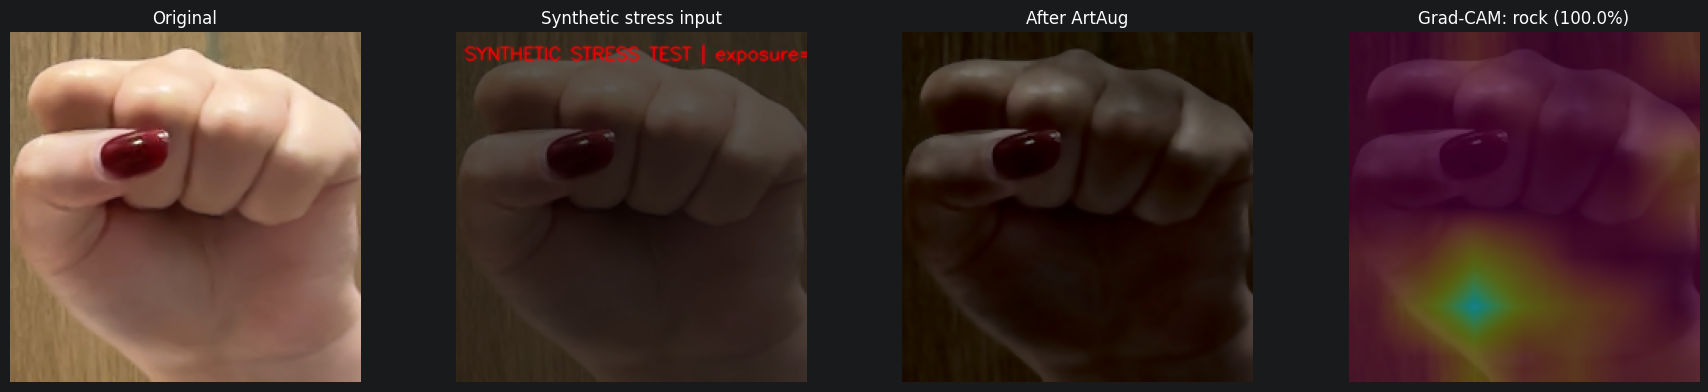

{'prediction': 'rock', 'confidence': 0.999509334564209, 'probabilities': array([2.2307097e-04, 9.9950933e-01, 2.6765809e-04], dtype=float32)}


In [7]:
demo_files = sorted((TEST_DIR / "rock").glob("*.jpg"))
if demo_files and SOTA_MODEL_PATH.exists():
    demo_result = predict_image(demo_files[0], exposure=0.35, blur_kernel=1, noise_level=0.0, use_artaug=True)
    print(demo_result)
else:
    print("Demo skipped: train the SOTA model and ensure test images are available")